In [1]:
import numpy as np
import matplotlib.pyplot as plt
import hcipy as hci

In [2]:
n_px = 512
dia = 48e-3

In [3]:
def super_gaussian(x, sigma, N):
    return np.exp(-np.power((x/sigma), N))

In [4]:
def find_N(n_px, radius, taper, delta=0.05):
    N = int(2*np.round(np.log(delta)/(np.log((radius*(1-2*taper/n_px))/radius)*2)))
    return N

In [5]:
grid = hci.make_pupil_grid(n_px, 1.05*dia)

In [6]:
pupil = hci.circular_aperture(dia)(grid)

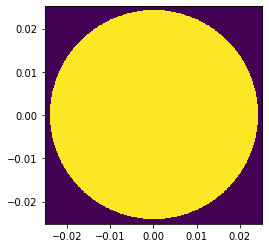

In [7]:
hci.imshow_field(pupil)

In [8]:
N = find_N(n_px, dia/2, taper=1, delta=0.1)

In [9]:
print(N)

588


In [10]:
smooth = super_gaussian(grid.as_('polar').r, dia/2, N)

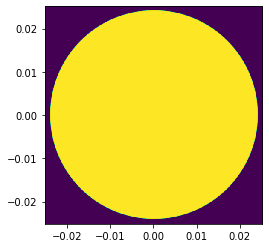

In [11]:
hci.imshow_field(hci.Field(smooth, grid))

In [12]:
print("relative area error:  {}".format(smooth.sum()/pupil.sum()-1.0))

relative area error:  -0.0019345638832407586
